In [1]:
import pandas as pd
import numpy as np

In [2]:
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    ConfusionMatrixDisplay,
    mean_absolute_error
)
from sklearn.inspection import permutation_importance

try:
  from xgboost import XGBClassifier
  Has_XGB = True
except:
  Has_XGB = False
  print("XGBoost available:", Has_XGB)

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})  # chart style
RS = 42

In [3]:
df = pd.read_csv("Unified_Leads.csv")


In [4]:
print("DataFrame Shape:", df.shape)
df.head()

DataFrame Shape: (27375, 15)


/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  cast_date_col = pd.to_datetime(column, errors="coerce")
/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  cast_date_col = pd.to_datetime(column, errors="coerce")
/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cast_date_col = pd.to_datetime(column, errors="coerce")


,Name,contact_number,Contact_email,creation_date,first_call_attempt,lead_status,lead_stage,lead_tag,assigned_to,last_call_date,last_call_time,references,campaign_name,source_type,source_name
0,Anjali Singh,9931980478,anjali.singh878@hotmail.com,03-02-2026 22:31,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
1,Kiran Bose,6474315136,kiran.bose601@example.com,03-02-2026 21:46,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,FACEBOOK_ADS,FACEBOOK_ADS
2,Karthik Malhotra,6753707898,karthik.malhotra329@example.com,03-02-2026 21:28,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
3,Anjali Sharma,9439163624,anjali.sharma85@example.com,03-02-2026 19:59,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
4,Sneha Kapoor,9878269840,sneha.kapoor46@gmail.com,03-02-2026 19:19,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM


In [5]:
df.columns = [c.strip().lower() for c in df.columns]

In [6]:
print("Shape", df.shape)

Shape (27375, 15)


In [7]:
display(df.head())
print("\nMissing values:"); display(df.isna().sum()[lambda s: s > 0])

,name,contact_number,contact_email,creation_date,first_call_attempt,lead_status,lead_stage,lead_tag,assigned_to,last_call_date,last_call_time,references,campaign_name,source_type,source_name
0,Anjali Singh,9931980478,anjali.singh878@hotmail.com,03-02-2026 22:31,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
1,Kiran Bose,6474315136,kiran.bose601@example.com,03-02-2026 21:46,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,FACEBOOK_ADS,FACEBOOK_ADS
2,Karthik Malhotra,6753707898,karthik.malhotra329@example.com,03-02-2026 21:28,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
3,Anjali Sharma,9439163624,anjali.sharma85@example.com,03-02-2026 19:59,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
4,Sneha Kapoor,9878269840,sneha.kapoor46@gmail.com,03-02-2026 19:19,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM



Missing values:


,0
first_call_attempt,6729
lead_tag,11416
last_call_date,6729
last_call_time,6729
references,27375


In [8]:
for c in df.select_dtypes(include=["object", "string"]).columns:
    df[c] = df[c].str.strip()

df = df.drop(columns=["references"])
df["assigned_to"] = df["assigned_to"].str.title()
DT = "%d-%m-%Y %H:%M"
df["creation_dt"]   = pd.to_datetime(df["creation_date"], format=DT)
df["first_call_dt"] = pd.to_datetime(df["first_call_attempt"], format=DT, errors="coerce")
df["last_call_dt"]  = pd.to_datetime(df["last_call_date"], format=DT, errors="coerce")
print("Date range:", df.creation_dt.min(), "->", df.creation_dt.max())
print("Duplicate contact numbers:", df.contact_number.duplicated().sum())

Date range: 2025-06-02 12:35:00 -> 2026-02-03 22:31:00
Duplicate contact numbers: 0


In [9]:
df["converted"] = (df["lead_stage"] == "CONVERTED").astype(int)
print(df.lead_stage.value_counts())
print("\nlead_stage vs lead_tag (shows leakage):")
display(pd.crosstab(df.lead_stage, df.lead_tag.fillna("(none)")))
resolved = df[df.lead_stage.isin(["CONVERTED", "LOST"])].copy()
pending  = df[~df.lead_stage.isin(["CONVERTED", "LOST"])].copy()
print(f"\nResolved: {len(resolved):,} | converted {resolved.converted.sum()} ({resolved.converted.mean():.1%}) | open: {len(pending):,}")

lead_stage
LOST                  11698
Prospect              10119
Follow Up Required     4713
CONVERTED               845
Name: count, dtype: int64

lead_stage vs lead_tag (shows leakage):


lead_tag,(none),already-purchased,call-not-connected,cold,hot,lost-to-competition,not-interested,warm
lead_stage,,,,,,,,
CONVERTED,845,0,0,0,0,0,0,0
Follow Up Required,7,0,0,4024,236,0,0,446
LOST,445,29,52,0,0,303,10869,0
Prospect,10119,0,0,0,0,0,0,0



Resolved: 12,543 | converted 845 (6.7%) | open: 14,832


In [10]:
CAT_COLS =["campaign", "course", "source_type", "assigned_to"]
UM_A = ["creation_hour", "creation_dow", "is_weekend", "is_refurbished", "dup_email"]
NUM_B = ["first_call_made", "log_hours_to_first_call", "first_call_hour"]

In [11]:
def course_of(name):
    low = str(name).lower()
    if "business accounting" in low or low.startswith("ba ") or low.endswith("-ba"): return "Accounting"
    if "python" in low: return "Python"
    if "data analytics" in low or low.endswith("-da"): return "Data Analytics"
    if "performance marketing" in low: return "Performance Marketing"
    if "digital marketing" in low or "dm" in low.split() or low.endswith("dm") or "- dm" in low: return "Digital Marketing"
    if "php" in low: return "PHP"
    if "ui/ux" in low: return "UI/UX"
    if "sap" in low: return "SAP"
    return "Other/Common"

In [12]:
def build_features(d, keep_campaigns=None, keep_agents=None):
    X = pd.DataFrame(index=d.index)
    X["campaign"]       = d["campaign_name"].str.strip()
    X["course"]         = X["campaign"].map(course_of)
    X["is_refurbished"] = X["campaign"].str.lower().str.contains("refurbished").astype(int)
    X["source_type"]    = d["source_type"].replace({"WALK_IN_LEAD": "OTHER", "NEODOVE_DIAL_PAD": "OTHER"})
    X["assigned_to"]    = d["assigned_to"].str.title().str.strip()
    X["creation_hour"]  = d["creation_dt"].dt.hour
    X["creation_dow"]   = d["creation_dt"].dt.dayofweek
    X["is_weekend"]     = (X["creation_dow"] >= 5).astype(int)
    X["dup_email"]      = d["contact_email"].duplicated(keep=False).astype(int)
    hrs = (d["first_call_dt"] - d["creation_dt"]).dt.total_seconds() / 3600
    X["first_call_made"]         = d["first_call_dt"].notna().astype(int)
    X["log_hours_to_first_call"] = np.log1p(hrs.clip(lower=0)).fillna(-1)
    X["first_call_hour"]         = d["first_call_dt"].dt.hour.fillna(-1)
    if keep_campaigns is not None: X.loc[~X.campaign.isin(keep_campaigns), "campaign"] = "Other"
    if keep_agents    is not None: X.loc[~X.assigned_to.isin(keep_agents), "assigned_to"] = "Other"
    return X

KEEP_CAMP  = resolved.campaign_name.value_counts()[lambda s: s >= 150].index.tolist()
KEEP_AGENT = resolved.assigned_to.value_counts()[lambda s: s >= 150].index.tolist()
X_all = build_features(resolved, KEEP_CAMP, KEEP_AGENT)  # feature table
y = resolved["converted"]                                # the answer column (0/1)
display(X_all.head())

,campaign,course,is_refurbished,source_type,assigned_to,creation_hour,creation_dow,is_weekend,dup_email,first_call_made,log_hours_to_first_call,first_call_hour
594,Data Analytics Knovista,Data Analytics,0,INSTAGRAM,Dharshana,10,3,0,0,1,3.311151,12.0
607,Data Analytics Knovista,Data Analytics,0,FACEBOOK_ADS,Megha S,8,3,0,0,1,1.808289,13.0
614,Data Analytics Knovista,Data Analytics,0,INSTAGRAM,Revathy Reghu,6,3,0,0,1,1.802809,12.0
616,Data Analytics Knovista,Data Analytics,0,INSTAGRAM,Megha S,4,3,0,0,1,2.263498,13.0
637,Data Analytics Knovista,Data Analytics,0,INSTAGRAM,Megha S,20,2,0,0,1,2.977229,15.0


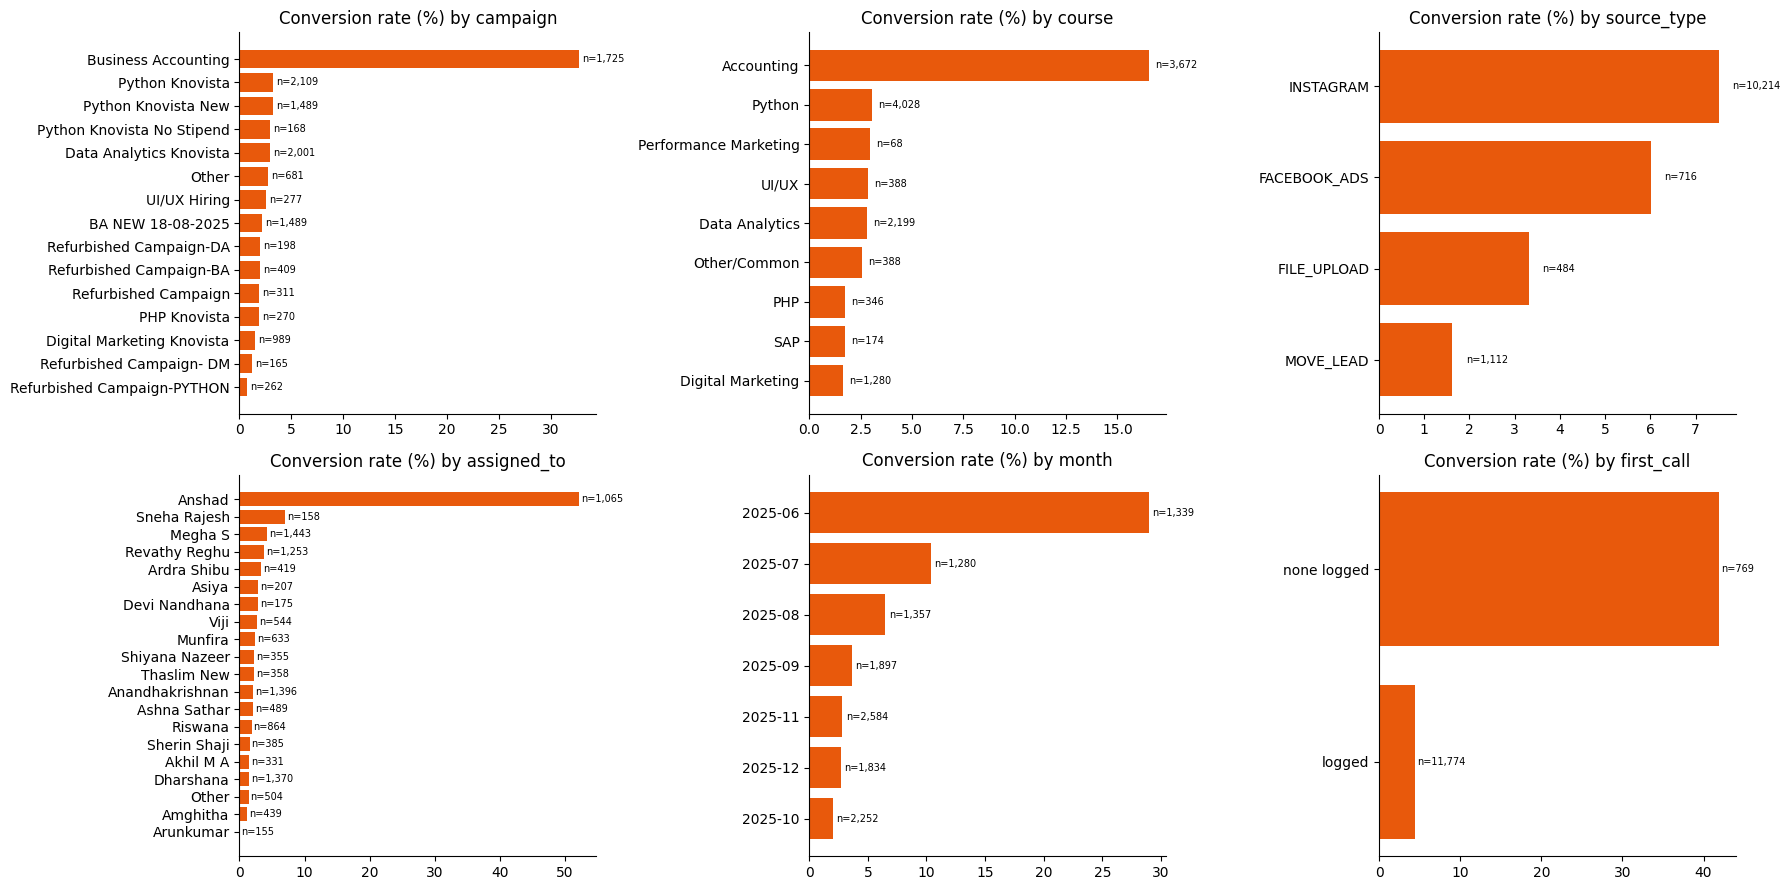

In [13]:
eda = resolved.assign(
  campaign=X_all.campaign,
  course=X_all.course,
  source_type=X_all.source_type,
  assigned_to=X_all.assigned_to,
  month=resolved.creation_dt.dt.to_period("M").astype(str),
  first_call=np.where(X_all.first_call_made == 1, "logged", "none logged")
)

fig, ax = plt.subplots(2, 3, figsize=(18, 9))
for a, col in zip(ax.ravel(), ["campaign", "course", "source_type", "assigned_to", "month", "first_call"]):
    t = eda.groupby(col).converted.agg(["mean", "size"]).sort_values("mean")
    t = t[t["size"] >= 30]
    a.barh(t.index.astype(str), t["mean"] * 100, color="#E8590C")
    for i, (m, n) in enumerate(zip(t["mean"], t["size"])):
        a.text(m * 100 + .3, i, f"n={n:,}", va="center", fontsize=7)
    a.set_title(f"Conversion rate (%) by {col}")
plt.tight_layout()
plt.show()

In [14]:
eda["ba_campaign"] = eda.campaign.eq("Business Accounting")
print("Conversion rate by month:")
display(eda.groupby("month").converted.agg(["size", "sum", "mean"]).round(3))
print("Business Accounting campaign vs everything else, by month:")
display(eda.pivot_table(index="month", columns="ba_campaign", values="converted", aggfunc="mean").round(3))
print("Executive 'Anshad' vs others, by month:")
display(eda.assign(anshad=eda.assigned_to.eq("Anshad")).pivot_table(index="month", columns="anshad", values="converted", aggfunc="mean").round(3))

Conversion rate by month:


,size,sum,mean
month,,,
2025-06,1339,388,0.290
2025-07,1280,133,0.104
2025-08,1357,88,0.065
2025-09,1897,69,0.036
2025-10,2252,45,0.020
2025-11,2584,73,0.028
2025-12,1834,49,0.027


Business Accounting campaign vs everything else, by month:


ba_campaign,False,True
month,,
2025-06,0.013,0.661
2025-07,0.027,0.180
2025-08,0.029,0.231
2025-09,0.032,0.064
2025-10,0.020,0.000
2025-11,0.028,NaN
2025-12,0.027,NaN


Executive 'Anshad' vs others, by month:


anshad,False,True
month,,
2025-06,0.014,0.868
2025-07,0.020,0.399
2025-08,0.029,0.385
2025-09,0.031,0.084
2025-10,0.020,0.000
2025-11,0.028,0.167
2025-12,0.027,NaN


In [15]:
def make_pipe(model, num, scale=False):
    ct = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False), CAT_COLS),
                            ("num", StandardScaler() if scale else "passthrough", num)])
    # one-hot: text -> 0/1 columns | unseen categories ignored | rare ones (<20) merged | scaler only for Logistic Regression
    return Pipeline([("prep", ct), ("model", model)])    # preprocessing + model in one object

def get_models(num, pos_weight):
    m = {
      "Logistic Regression": make_pipe(LogisticRegression(max_iter=2000, class_weight="balanced", C=0.5), num, True),
      "Decision Tree": make_pipe(DecisionTreeClassifier(max_depth=6, min_samples_leaf=40, class_weight="balanced", random_state=RS), num),
      "Random Forest": make_pipe(RandomForestClassifier(n_estimators=400, min_samples_leaf=10, class_weight="balanced_subsample",
                                                        n_jobs=-1, random_state=RS), num),
    }
    if Has_XGB:
        m["XGBoost"] = make_pipe(XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                               scale_pos_weight=pos_weight, eval_metric="logloss", random_state=RS, n_jobs=-1), num)
    else:
        m["Gradient Boosting"] = make_pipe(HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=250,
                                           l2_regularization=1.0, class_weight="balanced", random_state=RS), num)
    return m

def best_f1_threshold(yt, p):
    pr, rc, th = precision_recall_curve(yt, p); f = 2 * pr * rc / (pr + rc + 1e-9)
    return float(th[np.argmax(f[:-1])])

def scores(yt, p, thr):
    pred = (p >= thr).astype(int)
    return dict(Accuracy=accuracy_score(yt, pred), Precision=precision_score(yt, pred, zero_division=0), Recall=recall_score(yt, pred),
                F1=f1_score(yt, pred), ROC_AUC=roc_auc_score(yt, p), PR_AUC=average_precision_score(yt, p), Threshold=thr)

FEATURE_SETS = {"A: at lead creation": UM_A, "B: + first-call info": UM_A + NUM_B}
results, fitted, rocs = {}, {}, {}
for setname, num in FEATURE_SETS.items():
    cols = CAT_COLS + num
    Xtr, Xte, ytr, yte = train_test_split(X_all[cols], y, test_size=0.2, stratify=y, random_state=RS)
    pw = (ytr == 0).sum() / (ytr == 1).sum()             # imbalance ratio for XGBoost
    for name, mdl in get_models(num, pw).items():
        oof = cross_val_predict(mdl, Xtr, ytr, cv=StratifiedKFold(5, shuffle=True, random_state=RS), method="predict_proba")[:, 1]
        thr = best_f1_threshold(ytr, oof)
        mdl.fit(Xtr, ytr); p = mdl.predict_proba(Xte)[:, 1]
        results[(setname, name)] = {**scores(yte, p, thr), "CV_AUC": roc_auc_score(ytr, oof)}
        fitted[(setname, name)] = (mdl, Xte, yte, p, thr); rocs[(setname, name)] = roc_curve(yte, p)
        print("done:", setname, "|", name)

done: A: at lead creation | Logistic Regression
done: A: at lead creation | Decision Tree
done: A: at lead creation | Random Forest
done: A: at lead creation | XGBoost
done: B: + first-call info | Logistic Regression
done: B: + first-call info | Decision Tree
done: B: + first-call info | Random Forest
done: B: + first-call info | XGBoost


In [16]:
res = pd.DataFrame(results).T.round(3); res.index.names = ["Feature set", "Model"]

Best model (by test ROC-AUC): Random Forest | decision threshold: 0.912


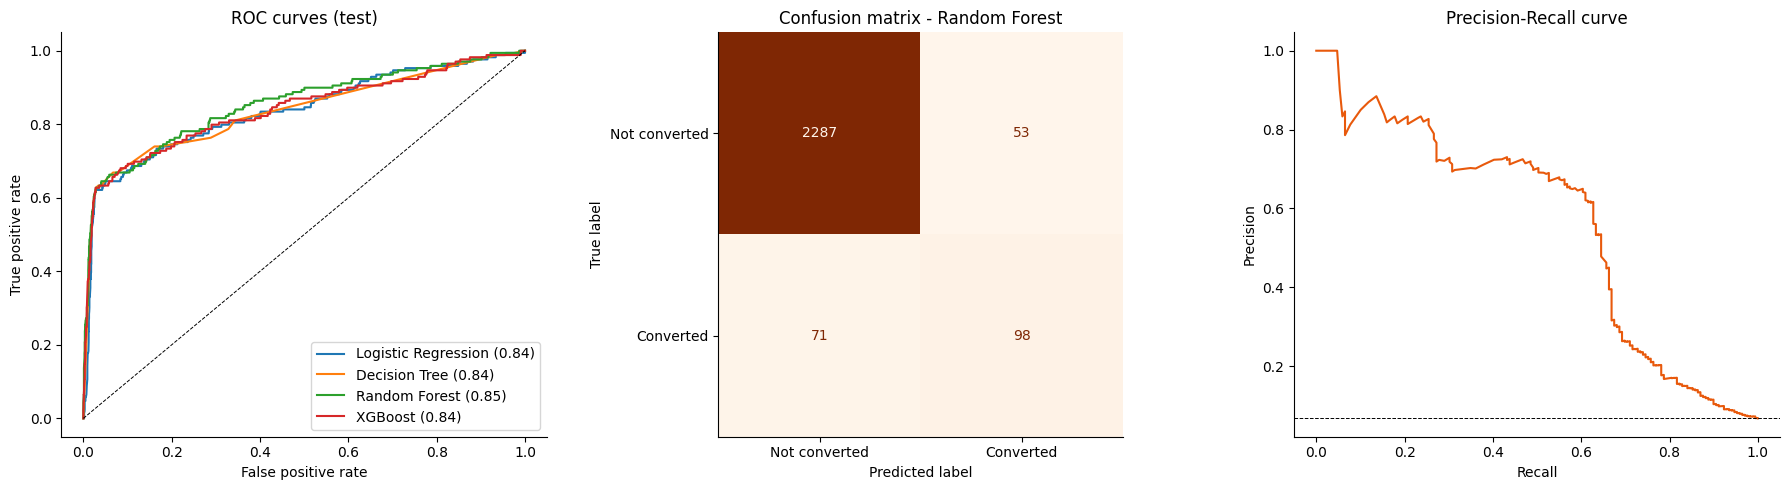

,size,sum,mean,lift,cum_capture
decile,,,,,
1,251,112,0.446,6.625,0.663
2,251,10,0.040,0.591,0.722
3,251,11,0.044,0.651,0.787
4,251,11,0.044,0.651,0.852
5,251,5,0.020,0.296,0.882
6,251,4,0.016,0.237,0.905
7,251,5,0.020,0.296,0.935
8,251,4,0.016,0.237,0.959
9,251,3,0.012,0.177,0.976


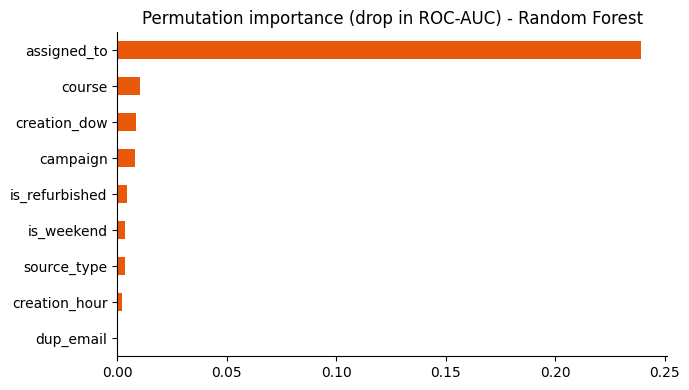

In [17]:
SET = "A: at lead creation"
best_name = res.loc[SET].sort_values("ROC_AUC", ascending=False).index[0]
mdl, Xte, yte, p, thr = fitted[(SET, best_name)]
print("Best model (by test ROC-AUC):", best_name, "| decision threshold:", round(thr, 3))

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for (s, n), (f, t, _) in rocs.items():
    if s == SET: ax[0].plot(f, t, label=f"{n} ({res.loc[(s, n), 'ROC_AUC']:.2f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=.7); ax[0].set(title="ROC curves (test)", xlabel="False positive rate", ylabel="True positive rate"); ax[0].legend()
ConfusionMatrixDisplay(confusion_matrix(yte, (p >= thr).astype(int)), display_labels=["Not converted", "Converted"]).plot(ax=ax[1], colorbar=False, cmap="Oranges")
ax[1].set_title(f"Confusion matrix - {best_name}")
pr, rc, _ = precision_recall_curve(yte, p); ax[2].plot(rc, pr, color="#E8590C"); ax[2].axhline(yte.mean(), color="k", ls="--", lw=.7)
ax[2].set(title="Precision-Recall curve", xlabel="Recall", ylabel="Precision")
plt.tight_layout(); plt.show()

#
d = pd.DataFrame({"y": yte.values, "p": p}).sort_values("p", ascending=False).reset_index(drop=True)
d["decile"] = np.arange(len(d)) * 10 // len(d) + 1
lift = d.groupby("decile").y.agg(["size", "sum", "mean"]); lift["lift"] = lift["mean"] / d.y.mean(); lift["cum_capture"] = lift["sum"].cumsum() / d.y.sum()
display(lift.round(3))                                   # lift = group rate / overall rate

pi = permutation_importance(mdl, Xte, yte, scoring="roc_auc", n_repeats=15, random_state=RS, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=Xte.columns).sort_values()
imp.plot.barh(color="#E8590C", figsize=(7, 4), title=f"Permutation importance (drop in ROC-AUC) - {best_name}"); plt.tight_layout(); plt.show()

In [18]:
tr_mask = resolved.creation_dt < "2025-10-01"; te_mask = ~tr_mask
rows = []
for setname, num in FEATURE_SETS.items():
    cols = CAT_COLS + num; pw = (y[tr_mask] == 0).sum() / (y[tr_mask] == 1).sum()
    for name, mdl_ in get_models(num, pw).items():
        mdl_.fit(X_all.loc[tr_mask, cols], y[tr_mask]); pt = mdl_.predict_proba(X_all.loc[te_mask, cols])[:, 1]
        rows.append({"Feature set": setname, "Model": name, "ROC_AUC": roc_auc_score(y[te_mask], pt),
                     "PR_AUC": average_precision_score(y[te_mask], pt), "Base rate": y[te_mask].mean()})
display(pd.DataFrame(rows).round(3))
print("Train:", tr_mask.sum(), "leads | Test:", te_mask.sum(), "leads")

,Feature set,Model,ROC_AUC,PR_AUC,Base rate
0,A: at lead creation,Logistic Regression,0.552,0.029,0.025
1,A: at lead creation,Decision Tree,0.528,0.027,0.025
2,A: at lead creation,Random Forest,0.565,0.032,0.025
3,A: at lead creation,XGBoost,0.546,0.030,0.025
4,B: + first-call info,Logistic Regression,0.539,0.027,0.025
5,B: + first-call info,Decision Tree,0.585,0.034,0.025
6,B: + first-call info,Random Forest,0.572,0.033,0.025
7,B: + first-call info,XGBoost,0.567,0.035,0.025


Train: 5873 leads | Test: 6670 leads


In [19]:
FINAL_COLS = CAT_COLS + UM_A
pw = (y == 0).sum() / (y == 1).sum()
final_model = get_models(UM_A, pw)[best_name].fit(X_all[FINAL_COLS], y)

def predict_leads(new_df):
    """new_df needs: creation_date, assigned_to, campaign_name, source_type, contact_email"""
    d = new_df.copy(); d.columns = [c.strip().lower() for c in d.columns]
    d["assigned_to"] = d["assigned_to"].str.strip().str.title()
    d["creation_dt"] = pd.to_datetime(d["creation_date"], format=DT)
    d["first_call_dt"] = pd.NaT
    X = build_features(d, KEEP_CAMP, KEEP_AGENT)[FINAL_COLS]
    s = final_model.predict_proba(X)[:, 1]
    out = d.assign(conversion_score=s.round(4), will_convert=(s >= thr).astype(int))
    out["priority"] = pd.cut(s, [-1, 0.2, 0.5, 2], labels=["LOW", "MEDIUM", "HIGH"])
    return out[["campaign_name", "assigned_to", "source_type", "conversion_score", "will_convert", "priority"]]

new_lead = pd.DataFrame([dict(creation_date="10-02-2026 11:30", contact_email="a@example.com", assigned_to="Revathy Reghu",
                              campaign_name="Python Knovista", source_type="INSTAGRAM")])

In [20]:
import joblib
from google.colab import files

Xp = build_features(pending, KEEP_CAMP, KEEP_AGENT)[FINAL_COLS]
pending["conversion_score"] = final_model.predict_proba(Xp)[:, 1]
q = pending.conversion_score.quantile([.7, .9]).values
pending["priority"] = np.where(pending.conversion_score >= q[1], "HIGH", np.where(pending.conversion_score >= q[0], "MEDIUM", "LOW"))
scored = pending.sort_values("conversion_score", ascending=False)[["name", "contact_number", "contact_email", "creation_date", "lead_stage",
                         "assigned_to", "campaign_name", "source_type", "conversion_score", "priority"]]
print(scored.priority.value_counts())
display(scored.head(15))
scored.to_csv("scored_open_leads.csv", index=False)
joblib.dump(dict(model=final_model, threshold=thr, keep_campaigns=KEEP_CAMP, keep_agents=KEEP_AGENT, features=FINAL_COLS), "lead_model.joblib")  # saved model



priority
LOW       10379
MEDIUM     2967
HIGH       1486
Name: count, dtype: int64


,name,contact_number,contact_email,creation_date,lead_stage,assigned_to,campaign_name,source_type,conversion_score,priority
16504,Karthik Bhat,9442589631,karthik.bhat433@outlook.com,29-08-2025 16:29,Prospect,Anshad,Business Accounting,INSTAGRAM,0.955438,HIGH
16505,Divya Gupta,7182996705,divya.gupta11@outlook.com,29-08-2025 16:28,Follow Up Required,Anshad,Business Accounting,INSTAGRAM,0.955438,HIGH
23182,Pooja Gupta,7159075723,pooja.gupta177@gmail.com,25-07-2025 16:24,Follow Up Required,Anshad,Business Accounting,INSTAGRAM,0.955438,HIGH
24102,Rahul Chopra,8805349982,rahul.chopra708@yahoo.com,11-07-2025 16:36,Follow Up Required,Anshad,Business Accounting,INSTAGRAM,0.955438,HIGH
26752,Kavya Malhotra,6860536334,kavya.malhotra975@yahoo.com,06-06-2025 16:18,Follow Up Required,Anshad,Business Accounting,INSTAGRAM,0.955438,HIGH
24707,Vikram Yadav,8325383498,vikram.yadav557@gmail.com,04-07-2025 16:35,Follow Up Required,Anshad,Business Accounting,INSTAGRAM,0.955438,HIGH
17961,Neha Kumar,9480902739,neha.kumar643@hotmail.com,15-08-2025 17:49,Follow Up Required,Anshad,Business Accounting,INSTAGRAM,0.955249,HIGH
26750,Neha Kumar,7053498080,neha.kumar27@gmail.com,06-06-2025 17:24,Follow Up Required,Anshad,Business Accounting,INSTAGRAM,0.955249,HIGH
16523,Meera Menon,8513297572,meera.menon197@hotmail.com,29-08-2025 14:46,Follow Up Required,Anshad,Business Accounting,INSTAGRAM,0.955198,HIGH
17507,Aditya Bhat,8292716354,aditya.bhat921@gmail.com,22-08-2025 14:25,Follow Up Required,Anshad,Business Accounting,INSTAGRAM,0.955198,HIGH


['lead_model.joblib']

In [21]:
# ---------- Cell 14: Accuracy, Precision, Recall, F1, ROC-AUC (uses results from Cell 8) ----------
from sklearn.metrics import classification_report

rows = []
for (setname, name), (mdl_, Xte_, yte_, p_, thr_) in fitted.items():
    pred = (p_ >= thr_).astype(int)                       # 0/1 prediction using the tuned threshold
    rows.append({
        "Feature set": setname,
        "Model": name,
        "Accuracy":  accuracy_score(yte_, pred),
        "Precision": precision_score(yte_, pred, zero_division=0),
        "Recall":    recall_score(yte_, pred),
        "F1 Score":  f1_score(yte_, pred),
        "ROC-AUC":   roc_auc_score(yte_, p_),             # uses probabilities, not 0/1
    })

metrics_table = pd.DataFrame(rows).round(3)
print("Test-set metrics for every model:")
display(metrics_table)

# Detailed report for the best deployable model (feature set A)
mdl_, Xte_, yte_, p_, thr_ = fitted[("A: at lead creation", best_name)]
pred = (p_ >= thr_).astype(int)
print(f"\nBest model: {best_name}  (decision threshold = {thr_:.3f})")
print(f"Accuracy : {accuracy_score(yte_, pred):.3f}")
print(f"Precision: {precision_score(yte_, pred, zero_division=0):.3f}")
print(f"Recall   : {recall_score(yte_, pred):.3f}")
print(f"F1 Score : {f1_score(yte_, pred):.3f}")
print(f"ROC-AUC  : {roc_auc_score(yte_, p_):.3f}")
print("\nClassification report:")
print(classification_report(yte_, pred, target_names=["Not converted", "Converted"], digits=3))

Test-set metrics for every model:


,Feature set,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,A: at lead creation,Logistic Regression,0.948,0.614,0.621,0.618,0.837
1,A: at lead creation,Decision Tree,0.948,0.613,0.627,0.620,0.837
2,A: at lead creation,Random Forest,0.951,0.649,0.580,0.612,0.854
3,A: at lead creation,XGBoost,0.949,0.616,0.627,0.622,0.840
4,B: + first-call info,Logistic Regression,0.941,0.559,0.621,0.588,0.839
5,B: + first-call info,Decision Tree,0.953,0.669,0.598,0.631,0.848
6,B: + first-call info,Random Forest,0.956,0.707,0.586,0.641,0.858
7,B: + first-call info,XGBoost,0.959,0.754,0.580,0.656,0.854



Best model: Random Forest  (decision threshold = 0.912)
Accuracy : 0.951
Precision: 0.649
Recall   : 0.580
F1 Score : 0.613
ROC-AUC  : 0.854

Classification report:
               precision    recall  f1-score   support

Not converted      0.970     0.977     0.974      2340
    Converted      0.649     0.580     0.613       169

     accuracy                          0.951      2509
    macro avg      0.809     0.779     0.793      2509
 weighted avg      0.948     0.951     0.949      2509

